# Multi-Dataset Cancer Classification Using Probabilistic Machine Learning

**Course:** Probability and Statistics (BAMAT207)  
**Track:** 6 — AI, Machine Learning & Probability  
**Primary model:** Gaussian Naive Bayes (implemented from scratch)  
**Comparison models:** Scikit-learn Gaussian Naive Bayes, Logistic Regression, balanced Logistic Regression, and a simple majority/prior baseline

## Project scope

This notebook studies **two separate classification experiments**:

1. **Breast tumour classification:** classify the Breast Cancer Wisconsin (Diagnostic) records as benign (0) or malignant (1) from 30 numerical cell-nucleus measurements.
2. **Cervical biopsy-outcome classification:** classify the `Biopsy` outcome (negative = 0, positive = 1) from selected demographic, habit and medical-history risk-factor variables in the UCI Cervical Cancer (Risk Factors) dataset.

The two datasets are analysed **separately**. Their rows and features are not merged because they describe different measurements and outcomes.

## Probability and Statistics concepts demonstrated

- Conditional probability
- Gaussian distributions and estimation of means/variances
- Likelihood estimation
- Bayes' theorem and posterior probabilities
- Correlation, class distribution and statistical summaries

> **Important limitation:** This is an academic analysis of existing datasets, not a clinically validated diagnostic tool. The cervical dataset's target is the recorded biopsy result; the notebook does not claim that risk factors alone can diagnose cancer in real patients.

## How to run this notebook

Run the notebook from top to bottom in Google Colab. Keep the existing breast dataset `data.csv` in `MyDrive/Cancer_Classification_Probabilistic_ML`. On the first run, if the cervical CSV is not already in that folder, a file upload prompt will let you upload `risk_factors_cervical_cancer.csv` or its ZIP. The notebook saves the uploaded file into the same Drive project folder, so you do not need to upload it on every future run.

The notebook also works locally if both CSV files are in the current working folder.

## 1. Imports, data paths, and output folders

This cell supports local runs from the repository and Google Colab. Locally, CSVs are read from `data/`. In Colab, the notebook stores them in the persistent Google Drive project folder and asks for an upload if either is missing. Generated plots and result tables are saved in `figures/` and `results/`.


In [1]:
import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report, roc_curve, make_scorer
)
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

# Detect Google Colab. In Colab, outputs and uploaded data are kept in Drive.
IN_COLAB = False
try:
    from google.colab import drive as colab_drive
    from google.colab import files as colab_files
    IN_COLAB = True
    colab_drive.mount('/content/drive', force_remount=False)
except ImportError:
    pass

if IN_COLAB:
    BASE_DIR = '/content/drive/MyDrive/Cancer_Classification_Probabilistic_ML'
    DATA_DIR = BASE_DIR
else:
    # Support running from the repository root or from a nested folder such as notebooks/.
    CWD = os.path.abspath(os.getcwd())
    if os.path.isdir(os.path.join(CWD, 'data')):
        BASE_DIR = CWD
        DATA_DIR = os.path.join(BASE_DIR, 'data')
    elif os.path.isdir(os.path.join(CWD, '..', 'data')):
        BASE_DIR = os.path.abspath(os.path.join(CWD, '..'))
        DATA_DIR = os.path.join(BASE_DIR, 'data')
    else:
        BASE_DIR = CWD
        DATA_DIR = BASE_DIR

FIG_DIR = os.path.join(BASE_DIR, 'figures')
RESULT_DIR = os.path.join(BASE_DIR, 'results')
os.makedirs(BASE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

BREAST_CSV_PATH = os.path.join(DATA_DIR, 'data.csv')
CERVICAL_CSV_PATH = os.path.join(DATA_DIR, 'risk_factors_cervical_cancer.csv')
CERVICAL_ZIP_PATH = os.path.join(DATA_DIR, 'cervical+cancer+risk+factors.zip')

# If the cervical CSV is absent but its ZIP is available, extract the expected CSV.
def extract_cervical_csv(zip_path, destination_path):
    expected_name = 'risk_factors_cervical_cancer.csv'
    with zipfile.ZipFile(zip_path, 'r') as zf:
        member = next((n for n in zf.namelist() if os.path.basename(n) == expected_name), None)
        if member is None:
            raise FileNotFoundError(f'{expected_name} was not found inside {zip_path}')
        with zf.open(member) as source, open(destination_path, 'wb') as target:
            target.write(source.read())
    return destination_path

if not os.path.exists(CERVICAL_CSV_PATH) and os.path.exists(CERVICAL_ZIP_PATH):
    extract_cervical_csv(CERVICAL_ZIP_PATH, CERVICAL_CSV_PATH)

# In Colab only, ask for missing datasets and save them in the Drive project folder.
if IN_COLAB and not os.path.exists(BREAST_CSV_PATH):
    print('Upload the breast dataset CSV named data.csv. It will be saved in the project folder.')
    uploaded = colab_files.upload()
    for name, content in uploaded.items():
        if name.lower().endswith('.csv'):
            with open(BREAST_CSV_PATH, 'wb') as f:
                f.write(content)
            break

if IN_COLAB and not os.path.exists(CERVICAL_CSV_PATH):
    print('Upload risk_factors_cervical_cancer.csv OR the provided cervical cancer ZIP. It will be saved in Drive.')
    uploaded = colab_files.upload()
    for name, content in uploaded.items():
        lower = name.lower()
        if lower.endswith('.csv') and 'cervical' in lower:
            with open(CERVICAL_CSV_PATH, 'wb') as f:
                f.write(content)
            break
        elif lower.endswith('.zip'):
            with open(CERVICAL_ZIP_PATH, 'wb') as f:
                f.write(content)
            extract_cervical_csv(CERVICAL_ZIP_PATH, CERVICAL_CSV_PATH)
            break

if not os.path.exists(BREAST_CSV_PATH):
    raise FileNotFoundError(
        f'Breast dataset not found at {BREAST_CSV_PATH}. Put data.csv in the data/ folder (local) or project folder (Colab).'
    )
if not os.path.exists(CERVICAL_CSV_PATH):
    raise FileNotFoundError(
        f'Cervical dataset not found at {CERVICAL_CSV_PATH}. Put risk_factors_cervical_cancer.csv in the data/ folder (local) or project folder (Colab).'
    )

print('Project folder :', BASE_DIR)
print('Data folder    :', DATA_DIR)
print('Breast data    :', BREAST_CSV_PATH)
print('Cervical data  :', CERVICAL_CSV_PATH)
print('Figures folder :', FIG_DIR)
print('Results folder :', RESULT_DIR)


Project folder : /mnt/data
Breast data    : /mnt/data/data.csv
Cervical data  : /mnt/data/risk_factors_cervical_cancer.csv
Figures folder : /mnt/data/figures
Results folder : /mnt/data/results


## 2. Load and inspect both datasets

The breast dataset contains numerical measurements and a diagnosis label. The cervical dataset contains risk-factor/history columns and several screening/diagnosis outcomes. We will use `Biopsy` as the cervical outcome and exclude the other diagnosis/screening result columns from its predictors to reduce label leakage.

In [2]:
breast_raw = pd.read_csv(BREAST_CSV_PATH)
cervical_raw = pd.read_csv(CERVICAL_CSV_PATH, na_values=['?', ' ?', ''])

print('BREAST DATASET — original shape:', breast_raw.shape)
display(breast_raw.head())
print('\nCERVICAL DATASET — original shape:', cervical_raw.shape)
display(cervical_raw.head())

print('\nCervical columns and raw missing-value counts:')
display(cervical_raw.isna().sum().sort_values(ascending=False).to_frame('missing_values'))

BREAST DATASET — original shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



CERVICAL DATASET — original shape: (858, 36)


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,IUD (years),STDs,STDs (number),STDs:condylomatosis,STDs:cervical condylomatosis,STDs:vaginal condylomatosis,STDs:vulvo-perineal condylomatosis,STDs:syphilis,STDs:pelvic inflammatory disease,STDs:genital herpes,STDs:molluscum contagiosum,STDs:AIDS,STDs:HIV,STDs:Hepatitis B,STDs:HPV,STDs: Number of diagnosis,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,0,0,0,0,0,0,0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,0,0,0,0,0,0,0,0
2,34,1.0,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,0,0,0,0,0,0,0,0
3,52,5.0,16.0,4.0,1.0,37.0,37.0,1.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,1,0,1,0,0,0,0,0
4,46,3.0,21.0,4.0,0.0,0.0,0.0,1.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,NaN,NaN,0,0,0,0,0,0,0,0



Cervical columns and raw missing-value counts:


,missing_values
STDs: Time since first diagnosis,787
STDs: Time since last diagnosis,787
IUD,117
IUD (years),117
Hormonal Contraceptives,108
Hormonal Contraceptives (years),108
STDs:HPV,105
STDs:AIDS,105
STDs:Hepatitis B,105
STDs:HIV,105


## 3. Clean the breast dataset

We remove the patient identifier and the entirely empty column. The diagnosis is encoded as benign = 0 and malignant = 1. The 30 remaining numerical features become model inputs.

In [3]:
breast_df = breast_raw.copy()
breast_duplicate_count = int(breast_df.duplicated().sum())
breast_df = breast_df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
breast_df['diagnosis'] = breast_df['diagnosis'].astype(str).str.strip().map({'B': 0, 'M': 1})

if breast_df['diagnosis'].isna().any():
    raise ValueError('Breast diagnosis encoding produced missing values. Check the source CSV.')

breast_y = breast_df['diagnosis'].astype(int)
breast_X = breast_df.drop(columns=['diagnosis']).apply(pd.to_numeric, errors='coerce')
breast_X = breast_X.replace([np.inf, -np.inf], np.nan)

print('Duplicate rows found in original breast data:', breast_duplicate_count)
print('Cleaned breast data shape (features + target):', (len(breast_df), breast_X.shape[1] + 1))
print('Breast feature count:', breast_X.shape[1])
print('Breast class counts:')
print(breast_y.map({0: 'Benign', 1: 'Malignant'}).value_counts())
print('Missing values in breast feature columns:', int(breast_X.isna().sum().sum()))

Duplicate rows found in original breast data: 0
Cleaned breast data shape (features + target): (569, 31)
Breast feature count: 30
Breast class counts:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64
Missing values in breast feature columns: 0


## 4. Clean the cervical dataset and define a leakage-safe target

The source has 858 rows, 36 columns and some values recorded as `?`. We convert those values to missing numeric values. We use `Biopsy` as the target (0 = negative, 1 = positive).

We **exclude** `Dx:Cancer`, `Dx:CIN`, `Dx:HPV`, `Dx`, `Hinselmann`, `Schiller` and `Citology` as predictors because these are diagnosis/screening outcomes rather than the risk-factor inputs we want to study. We also remove exact duplicate rows before splitting so identical complete records are not copied across training and test sets. This is a cautious data-preparation choice, and the counts before/after removal are printed below.

In [4]:
CERVICAL_TARGET = 'Biopsy'
CERVICAL_OUTCOME_COLUMNS = [
    'Dx:Cancer', 'Dx:CIN', 'Dx:HPV', 'Dx',
    'Hinselmann', 'Schiller', 'Citology'
]

cervical_numeric = cervical_raw.copy()
for col in cervical_numeric.columns:
    cervical_numeric[col] = pd.to_numeric(cervical_numeric[col], errors='coerce')

if CERVICAL_TARGET not in cervical_numeric.columns:
    raise KeyError(f"Expected target column '{CERVICAL_TARGET}' was not found in the cervical dataset.")

cervical_rows_before = len(cervical_numeric)
cervical_duplicates = int(cervical_numeric.duplicated().sum())
cervical_numeric = cervical_numeric.drop_duplicates().reset_index(drop=True)
cervical_rows_after = len(cervical_numeric)

cervical_y = cervical_numeric[CERVICAL_TARGET]
valid_target = cervical_y.isin([0, 1])
cervical_numeric = cervical_numeric.loc[valid_target].reset_index(drop=True)
cervical_y = cervical_numeric[CERVICAL_TARGET].astype(int)

columns_to_exclude = [CERVICAL_TARGET] + [
    c for c in CERVICAL_OUTCOME_COLUMNS if c in cervical_numeric.columns
]
cervical_X = cervical_numeric.drop(columns=columns_to_exclude).copy()
cervical_X = cervical_X.replace([np.inf, -np.inf], np.nan)

print('Rows before duplicate removal:', cervical_rows_before)
print('Exact duplicate rows removed:', cervical_duplicates)
print('Rows after duplicate removal:', cervical_rows_after)
print('Cleaned cervical rows used:', len(cervical_numeric))
print('Cervical risk-factor predictors before train-only filtering:', cervical_X.shape[1])
print('Cervical target counts (0 = biopsy negative, 1 = biopsy positive):')
print(cervical_y.value_counts().sort_index())
print('Positive biopsy fraction: {:.2%}'.format(cervical_y.mean()))
print('Cervical missing values across predictor cells:', int(cervical_X.isna().sum().sum()))

print('\nExcluded diagnosis/screening outcome columns:', columns_to_exclude)

Rows before duplicate removal: 858
Exact duplicate rows removed: 23
Rows after duplicate removal: 835
Cleaned cervical rows used: 835
Cervical risk-factor predictors before train-only filtering: 28
Cervical target counts (0 = biopsy negative, 1 = biopsy positive):
Biopsy
0    781
1     54
Name: count, dtype: int64
Positive biopsy fraction: 6.47%
Cervical missing values across predictor cells: 3485

Excluded diagnosis/screening outcome columns: ['Biopsy', 'Dx:Cancer', 'Dx:CIN', 'Dx:HPV', 'Dx', 'Hinselmann', 'Schiller', 'Citology']


## 5. Exploratory Data Analysis (EDA)

EDA means examining the dataset before fitting the models. We inspect feature summaries, class balance, missingness, distributions and correlations. The breast and cervical graphs are saved into the project's `figures` folder.

BREAST DATA — statistical summary


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


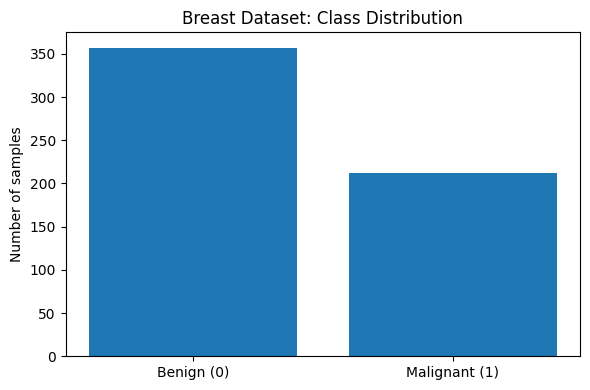

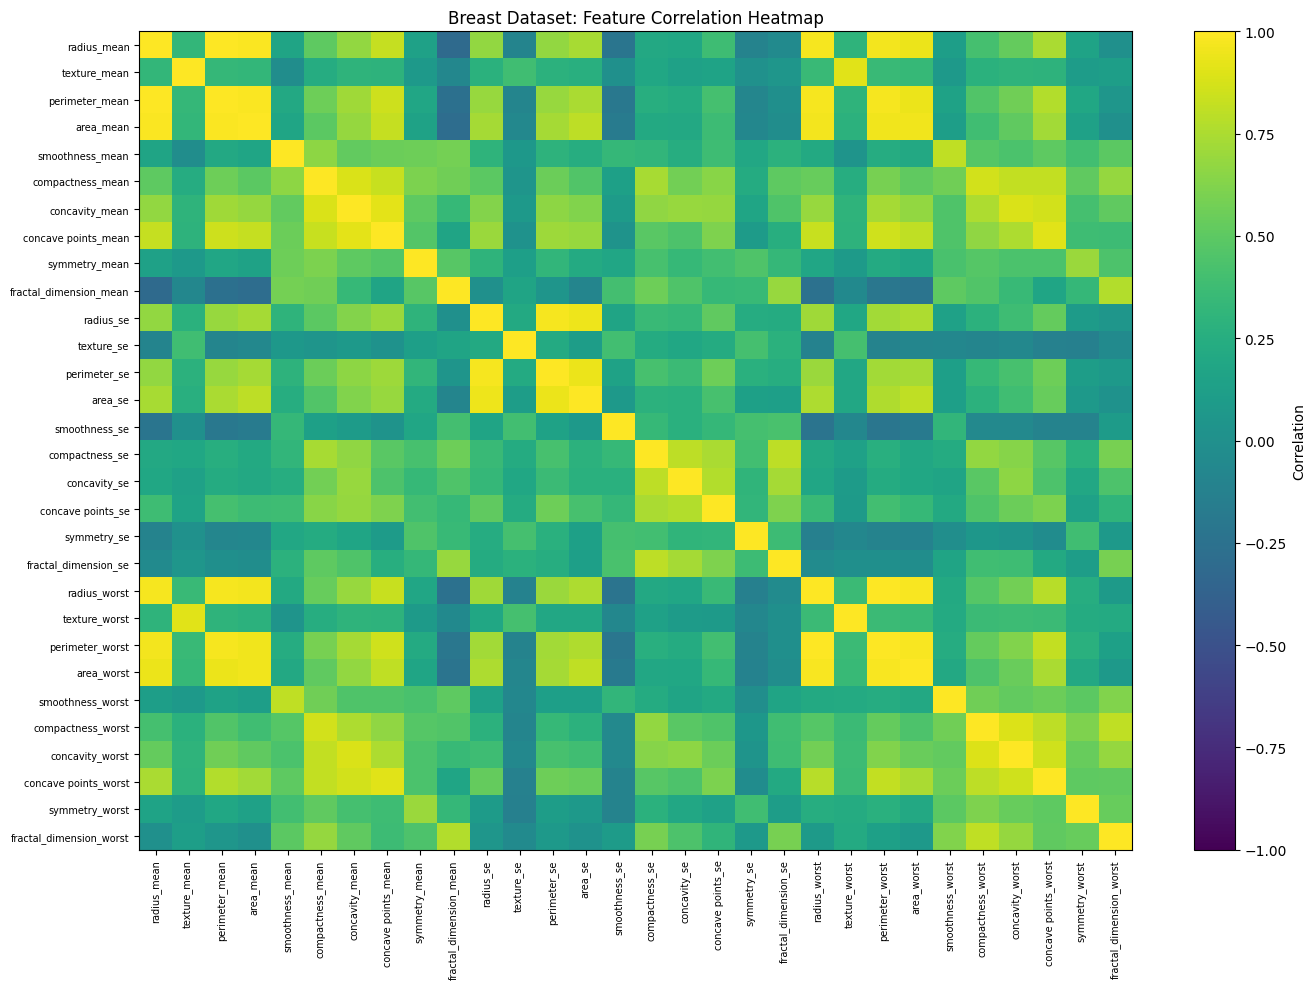

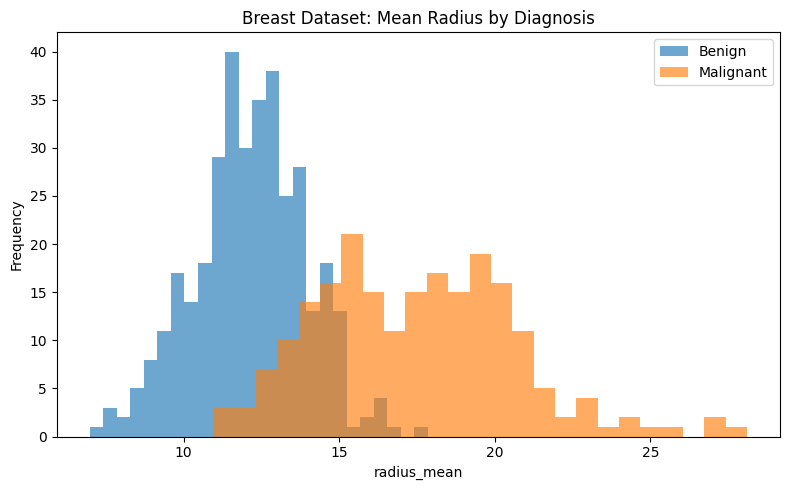

In [5]:
print('BREAST DATA — statistical summary')
display(breast_X.describe().T)

breast_class_counts = breast_y.value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Benign (0)', 'Malignant (1)'], breast_class_counts.values)
ax.set_title('Breast Dataset: Class Distribution')
ax.set_ylabel('Number of samples')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'breast_class_distribution.png'), dpi=220, bbox_inches='tight')
plt.show()

breast_corr = breast_X.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(14, 10))
image = ax.imshow(breast_corr, aspect='auto', interpolation='nearest', vmin=-1, vmax=1)
fig.colorbar(image, ax=ax, label='Correlation')
ax.set_xticks(range(len(breast_corr.columns)))
ax.set_xticklabels(breast_corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(breast_corr.columns)))
ax.set_yticklabels(breast_corr.columns, fontsize=7)
ax.set_title('Breast Dataset: Feature Correlation Heatmap')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'breast_correlation_heatmap.png'), dpi=220, bbox_inches='tight')
plt.show()

if 'radius_mean' in breast_X.columns:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(breast_X.loc[breast_y == 0, 'radius_mean'].dropna(), bins=25, alpha=0.65, label='Benign')
    ax.hist(breast_X.loc[breast_y == 1, 'radius_mean'].dropna(), bins=25, alpha=0.65, label='Malignant')
    ax.set_title('Breast Dataset: Mean Radius by Diagnosis')
    ax.set_xlabel('radius_mean')
    ax.set_ylabel('Frequency')
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, 'breast_radius_distribution.png'), dpi=220, bbox_inches='tight')
    plt.show()

CERVICAL DATA — statistical summary of risk-factor inputs


,count,mean,std,min,25%,50%,75%,max
Age,835.0,27.023952,8.482986,13.0,21.0,26.0,32.0,84.0
Number of sexual partners,810.0,2.551852,1.676686,1.0,2.0,2.0,3.0,28.0
First sexual intercourse,828.0,17.020531,2.817000,10.0,15.0,17.0,18.0,32.0
Num of pregnancies,779.0,2.304236,1.455817,0.0,1.0,2.0,3.0,11.0
Smokes,822.0,0.149635,0.356930,0.0,0.0,0.0,0.0,1.0
Smokes (years),822.0,1.253850,4.140727,0.0,0.0,0.0,0.0,37.0
Smokes (packs/year),822.0,0.465823,2.256273,0.0,0.0,0.0,0.0,37.0
Hormonal Contraceptives,732.0,0.651639,0.476777,0.0,0.0,1.0,1.0,1.0
Hormonal Contraceptives (years),732.0,2.302916,3.794180,0.0,0.0,0.5,3.0,30.0
IUD,723.0,0.114799,0.319000,0.0,0.0,0.0,0.0,1.0


Cervical missing values by feature (highest first)


,missing_count,missing_percent
STDs: Time since first diagnosis,764,91.497006
STDs: Time since last diagnosis,764,91.497006
IUD,112,13.413174
IUD (years),112,13.413174
Hormonal Contraceptives (years),103,12.335329
Hormonal Contraceptives,103,12.335329
STDs,100,11.976048
STDs:cervical condylomatosis,100,11.976048
STDs:condylomatosis,100,11.976048
STDs (number),100,11.976048


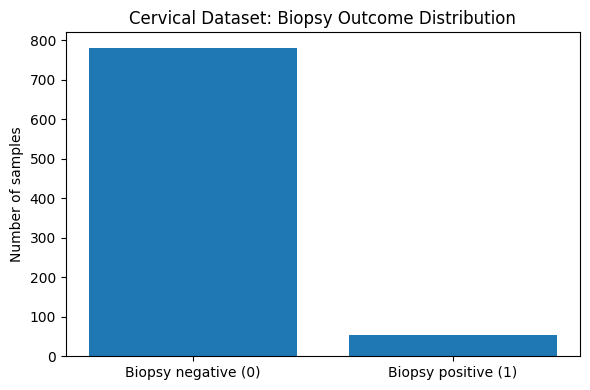

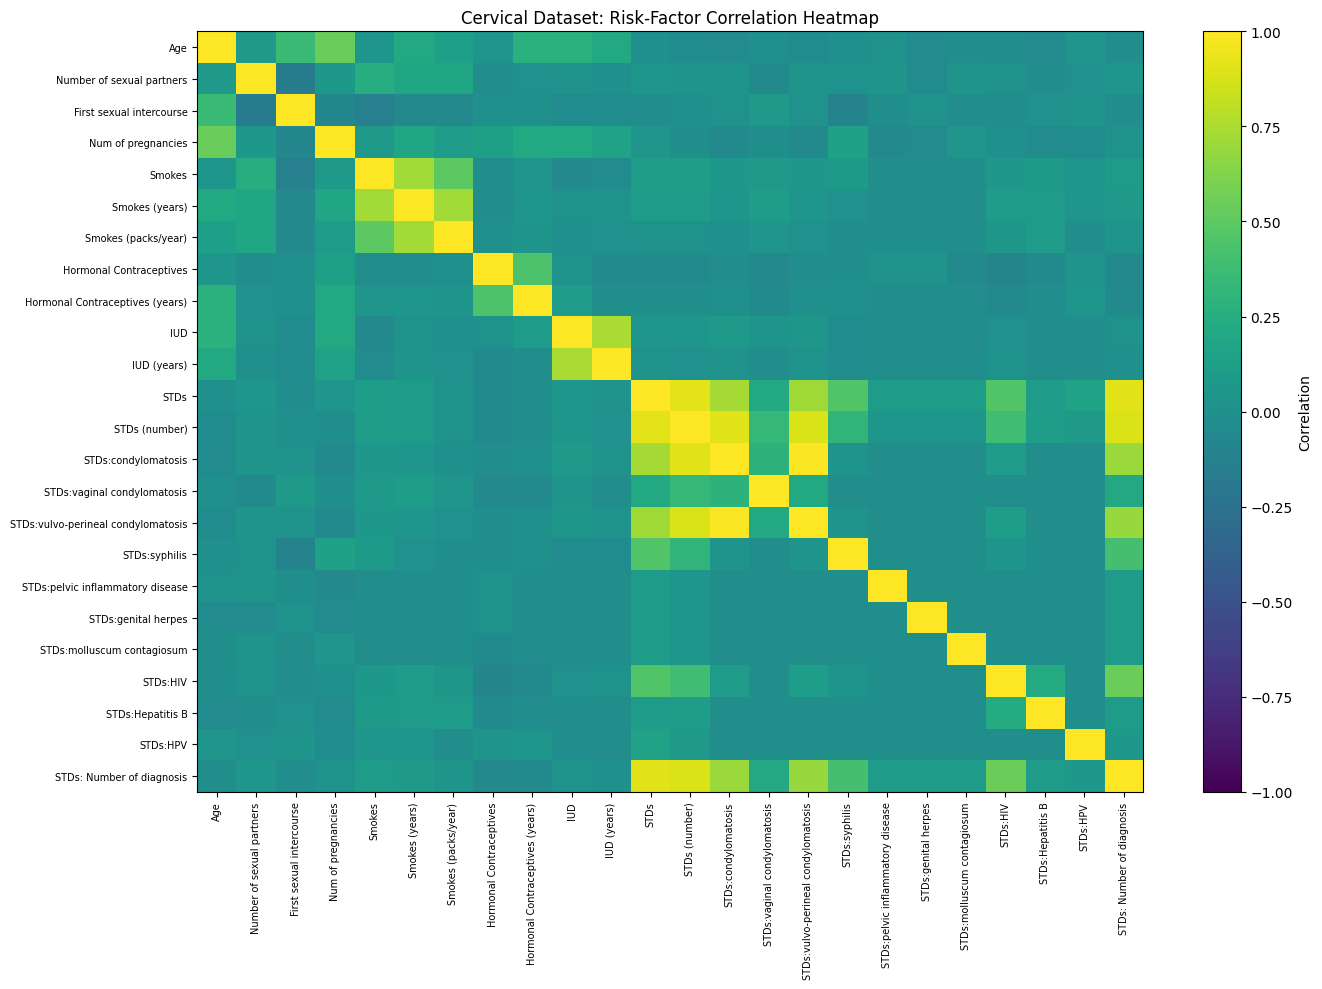

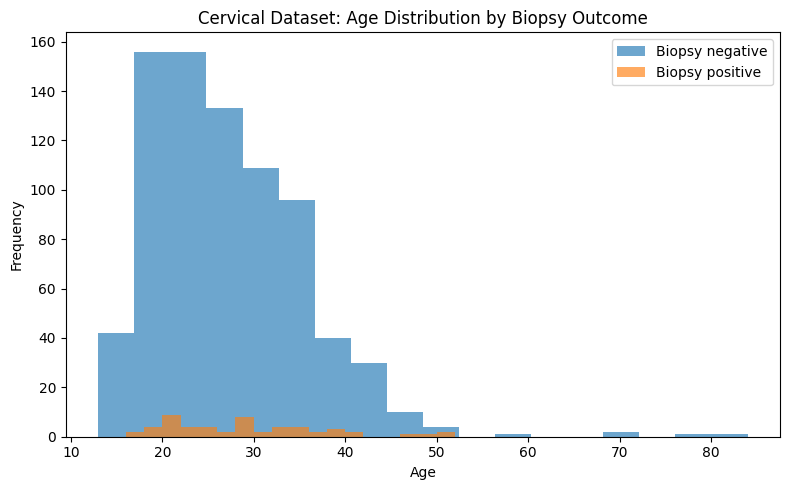

Note: the cervical target is imbalanced. Accuracy alone can be misleading; recall, F1, balanced accuracy and precision-recall AUC are also reported.


In [6]:
print('CERVICAL DATA — statistical summary of risk-factor inputs')
display(cervical_X.describe().T)

print('Cervical missing values by feature (highest first)')
cervical_missing = cervical_X.isna().sum().sort_values(ascending=False).to_frame('missing_count')
cervical_missing['missing_percent'] = 100 * cervical_missing['missing_count'] / len(cervical_X)
display(cervical_missing.head(12))

cervical_class_counts = cervical_y.value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Biopsy negative (0)', 'Biopsy positive (1)'], cervical_class_counts.values)
ax.set_title('Cervical Dataset: Biopsy Outcome Distribution')
ax.set_ylabel('Number of samples')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'cervical_biopsy_class_distribution.png'), dpi=220, bbox_inches='tight')
plt.show()

# For EDA only, omit columns that are over 50% missing in the full dataset.
# The model's actual feature filtering is determined from training data later.
cervical_eda_drop = cervical_X.columns[cervical_X.isna().mean() > 0.50].tolist()
cervical_eda_X = cervical_X.drop(columns=cervical_eda_drop)
cervical_eda_X = cervical_eda_X.loc[:, cervical_eda_X.nunique(dropna=True) > 1]
cervical_corr = cervical_eda_X.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(14, 10))
image = ax.imshow(cervical_corr, aspect='auto', interpolation='nearest', vmin=-1, vmax=1)
fig.colorbar(image, ax=ax, label='Correlation')
ax.set_xticks(range(len(cervical_corr.columns)))
ax.set_xticklabels(cervical_corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(cervical_corr.columns)))
ax.set_yticklabels(cervical_corr.columns, fontsize=7)
ax.set_title('Cervical Dataset: Risk-Factor Correlation Heatmap')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'cervical_correlation_heatmap.png'), dpi=220, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(cervical_X.loc[cervical_y == 0, 'Age'].dropna(), bins=18, alpha=0.65, label='Biopsy negative')
ax.hist(cervical_X.loc[cervical_y == 1, 'Age'].dropna(), bins=18, alpha=0.65, label='Biopsy positive')
ax.set_title('Cervical Dataset: Age Distribution by Biopsy Outcome')
ax.set_xlabel('Age')
ax.set_ylabel('Frequency')
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'cervical_age_distribution.png'), dpi=220, bbox_inches='tight')
plt.show()

print('Note: the cervical target is imbalanced. Accuracy alone can be misleading; recall, F1, balanced accuracy and precision-recall AUC are also reported.')

## 6. Shared modelling functions

The following shared code keeps the experiments consistent:

- 80% training data and 20% test data, with a stratified split and fixed random seed.
- Missingness and constant-column decisions are determined using the training data only.
- Median imputation is fitted on the training data, then applied to the test data.
- Gaussian Naive Bayes is implemented from scratch and checked against Scikit-learn.
- Logistic Regression, class-balanced Logistic Regression and a prior baseline are included.
- Metrics include accuracy, balanced accuracy, precision, recall, F1, ROC-AUC and average precision (PR-AUC).

For the cervical experiment, Gaussian Naive Bayes is applied to numeric-coded risk/history features. Since some inputs are binary or discrete rather than truly continuous, its Gaussian assumption is an approximation and will be discussed as a limitation.

In [7]:
class GaussianNaiveBayesScratch:
    """Gaussian Naive Bayes implementation using NumPy and log probabilities."""
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        if X.ndim != 2 or X.shape[0] != len(y):
            raise ValueError('X must be 2D and have the same number of rows as y.')
        if not np.isfinite(X).all():
            raise ValueError('X contains NaN or infinite values after imputation.')

        self.classes_ = np.sort(np.unique(y))
        self.means_ = {}
        self.variances_ = {}
        self.priors_ = {}
        global_variance = np.var(X, axis=0)
        self.epsilon_ = self.var_smoothing * np.max(global_variance)

        for c in self.classes_:
            X_c = X[y == c]
            self.means_[c] = np.mean(X_c, axis=0)
            self.variances_[c] = np.var(X_c, axis=0) + self.epsilon_
            self.priors_[c] = len(X_c) / len(X)
        return self

    def _joint_log_likelihood(self, X):
        X = np.asarray(X, dtype=float)
        scores = []
        for c in self.classes_:
            mean = self.means_[c]
            variance = self.variances_[c]
            log_gaussian = -0.5 * np.log(2 * np.pi * variance) - ((X - mean) ** 2) / (2 * variance)
            scores.append(np.log(self.priors_[c]) + np.sum(log_gaussian, axis=1))
        return np.vstack(scores).T

    def predict_proba(self, X):
        log_scores = self._joint_log_likelihood(X)
        log_scores = log_scores - np.max(log_scores, axis=1, keepdims=True)
        scores = np.exp(log_scores)
        return scores / scores.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


def prep_train_test(X, y, dataset_name, test_size=0.20, random_state=42, max_missing_fraction=0.50):
    """Split first; choose columns and fit imputer on training data only."""
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )
    high_missing = X_train_raw.columns[X_train_raw.isna().mean() > max_missing_fraction].tolist()
    X_train_raw = X_train_raw.drop(columns=high_missing)
    X_test_raw = X_test_raw.drop(columns=high_missing)

    constant_cols = [c for c in X_train_raw.columns if X_train_raw[c].nunique(dropna=True) <= 1]
    X_train_raw = X_train_raw.drop(columns=constant_cols)
    X_test_raw = X_test_raw.drop(columns=constant_cols)

    if X_train_raw.shape[1] == 0:
        raise ValueError(f'No features remain for {dataset_name} after preprocessing.')

    imputer = SimpleImputer(strategy='median')
    X_train_imp_array = imputer.fit_transform(X_train_raw)
    X_test_imp_array = imputer.transform(X_test_raw)
    columns = X_train_raw.columns.tolist()
    X_train_imp = pd.DataFrame(X_train_imp_array, columns=columns, index=X_train_raw.index)
    X_test_imp = pd.DataFrame(X_test_imp_array, columns=columns, index=X_test_raw.index)

    return {
        'name': dataset_name, 'X_train_raw': X_train_raw, 'X_test_raw': X_test_raw,
        'X_train': X_train_imp, 'X_test': X_test_imp,
        'y_train': y_train.astype(int), 'y_test': y_test.astype(int),
        'imputer': imputer, 'dropped_high_missing': high_missing,
        'dropped_constant': constant_cols, 'features': columns,
    }


def gaussian_pdf(x, mean, variance):
    variance = max(float(variance), 1e-12)
    return (1 / np.sqrt(2 * np.pi * variance)) * np.exp(-((x - mean) ** 2) / (2 * variance))


def run_single_feature_bayes_demo(prepared, feature_name, class_names):
    """Illustrate a one-feature likelihood/Bayes calculation; not the full classifier."""
    if feature_name not in prepared['features']:
        print(f'Skipping single-feature example: {feature_name} is not available after training-only filtering.')
        return None
    X_train = prepared['X_train']
    X_test = prepared['X_test']
    y_train = prepared['y_train']
    y_test = prepared['y_test']
    x_value = float(X_test.iloc[0][feature_name])

    prior = {c: float((y_train == c).mean()) for c in sorted(y_train.unique())}
    likelihood = {}
    for c in sorted(y_train.unique()):
        class_values = X_train.loc[y_train == c, feature_name].to_numpy(dtype=float)
        mu = float(np.mean(class_values))
        var = float(np.var(class_values, ddof=0))
        likelihood[c] = gaussian_pdf(x_value, mu, var)
        print(f'{class_names[c]}: training mean={mu:.5f}, variance={var:.5f}, prior={prior[c]:.5f}')
        print(f'  Gaussian density f({x_value:.5f} | {class_names[c]}) = {likelihood[c]:.8f}')

    unnormalized = {c: prior[c] * likelihood[c] for c in prior}
    denom = sum(unnormalized.values())
    posterior = {c: unnormalized[c] / denom for c in prior} if denom > 0 else {c: np.nan for c in prior}
    predicted = max(posterior, key=posterior.get)
    actual = int(y_test.iloc[0])
    print('\nFirst test sample feature:', feature_name, '=', x_value)
    print('Actual target:', class_names[actual])
    print('Posterior from this ONE FEATURE only:')
    for c in posterior:
        print(f'  P({class_names[c]} | {feature_name}) = {posterior[c]:.4%}')
    print('One-feature illustrative prediction:', class_names[predicted])
    print('Reminder: the full Gaussian Naive Bayes model combines all retained features.')
    return {'feature': feature_name, 'value': x_value, 'actual': actual, 'posterior': posterior, 'predicted': predicted}


def evaluate_probability_model(y_true, y_pred, positive_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision (positive class)': precision_score(y_true, y_pred, zero_division=0),
        'Recall (positive class)': recall_score(y_true, y_pred, zero_division=0),
        'F1 (positive class)': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, positive_prob),
        'Average Precision (PR-AUC)': average_precision_score(y_true, positive_prob),
    }


def run_experiment(prepared, class_names, prefix):
    X_train = prepared['X_train']
    X_test = prepared['X_test']
    X_train_raw = prepared['X_train_raw']
    X_test_raw = prepared['X_test_raw']
    y_train = prepared['y_train']
    y_test = prepared['y_test']

    # Primary model implemented from scratch.
    scratch = GaussianNaiveBayesScratch(var_smoothing=1e-9).fit(X_train.values, y_train.values)
    pred_scratch = scratch.predict(X_test.values)
    prob_scratch = scratch.predict_proba(X_test.values)[:, list(scratch.classes_).index(1)]

    # Standard library validation model, fit on the same imputed training data.
    sklearn_gnb = GaussianNB(var_smoothing=1e-9).fit(X_train.values, y_train.values)
    pred_gnb = sklearn_gnb.predict(X_test.values)
    prob_gnb = sklearn_gnb.predict_proba(X_test.values)[:, list(sklearn_gnb.classes_).index(1)]

    # Logistic Regression: imputer and scaling are fitted on the training data only.
    logistic = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=3000, random_state=42))
    ])
    logistic.fit(X_train_raw, y_train)
    pred_lr = logistic.predict(X_test_raw)
    prob_lr = logistic.predict_proba(X_test_raw)[:, list(logistic.classes_).index(1)]

    # Class-balanced logistic regression is especially informative for rare positive labels.
    logistic_balanced = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42))
    ])
    logistic_balanced.fit(X_train_raw, y_train)
    pred_lrb = logistic_balanced.predict(X_test_raw)
    prob_lrb = logistic_balanced.predict_proba(X_test_raw)[:, list(logistic_balanced.classes_).index(1)]

    baseline = DummyClassifier(strategy='prior').fit(X_train_raw, y_train)
    pred_base = baseline.predict(X_test_raw)
    prob_base = baseline.predict_proba(X_test_raw)[:, list(baseline.classes_).index(1)]

    preds = {
        'Gaussian Naive Bayes (scratch)': (pred_scratch, prob_scratch),
        'Scikit-learn GaussianNB': (pred_gnb, prob_gnb),
        'Logistic Regression': (pred_lr, prob_lr),
        'Balanced Logistic Regression': (pred_lrb, prob_lrb),
        'Prior baseline': (pred_base, prob_base),
    }

    metric_rows = []
    prediction_table = pd.DataFrame({'Actual': y_test.values})
    prediction_table['Actual label'] = prediction_table['Actual'].map(class_names)
    for model_name, (pred, prob) in preds.items():
        metric_rows.append({
            'Dataset': prepared['name'], 'Model': model_name,
            **evaluate_probability_model(y_test, pred, prob)
        })
        prediction_table[f'{model_name} prediction'] = pred
        prediction_table[f'{model_name} P(positive)'] = prob

    metrics_df = pd.DataFrame(metric_rows)
    prediction_table.to_csv(os.path.join(RESULT_DIR, f'{prefix}_test_predictions.csv'), index=False)

    # Verify scratch implementation against Scikit-learn.
    max_prob_difference = float(np.max(np.abs(prob_scratch - prob_gnb)))
    differing_predictions = int(np.sum(pred_scratch != pred_gnb))
    validation = {
        'Dataset': prepared['name'],
        'Differing predictions': differing_predictions,
        'Maximum absolute positive-probability difference': max_prob_difference,
        'Scratch epsilon': float(scratch.epsilon_),
        'Scikit-learn epsilon': float(sklearn_gnb.epsilon_),
    }

    # Confusion matrices in a compact grid.
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    axes = axes.ravel()
    for ax, (model_name, (pred, prob)) in zip(axes, preds.items()):
        disp = ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]), display_labels=[class_names[0], class_names[1]])
        disp.plot(ax=ax, colorbar=False, values_format='d')
        ax.set_title(model_name, fontsize=9)
    for ax in axes[len(preds):]:
        ax.axis('off')
    fig.suptitle(f'{prepared["name"]}: Test-Set Confusion Matrices', fontsize=14)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f'{prefix}_confusion_matrices.png'), dpi=220, bbox_inches='tight')
    plt.show()

    # ROC curves. Scratch and library GaussianNB overlap if validation succeeds, so plot one representative GNB curve.
    fig, ax = plt.subplots(figsize=(8, 6))
    roc_plot_models = [
        ('Gaussian Naive Bayes', prob_scratch),
        ('Logistic Regression', prob_lr),
        ('Balanced Logistic Regression', prob_lrb),
        ('Prior baseline', prob_base),
    ]
    for label, prob in roc_plot_models:
        fpr, tpr, _ = roc_curve(y_test, prob)
        auc_value = roc_auc_score(y_test, prob)
        ax.plot(fpr, tpr, label=f'{label} (AUC = {auc_value:.3f})')
    ax.plot([0, 1], [0, 1], linestyle='--', label='Random ranking')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate / Recall')
    ax.set_title(f'{prepared["name"]}: ROC Curve Comparison')
    ax.legend(loc='lower right', fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f'{prefix}_roc_curves.png'), dpi=220, bbox_inches='tight')
    plt.show()

    # Predicted positive-class probability distributions.
    fig, ax = plt.subplots(figsize=(8, 5))
    for class_value, class_label in class_names.items():
        ax.hist(prob_scratch[y_test.to_numpy() == class_value], bins=15, alpha=0.60, label=f'Actual {class_label}')
    ax.set_xlabel('Predicted probability of positive class')
    ax.set_ylabel('Number of test samples')
    ax.set_title(f'{prepared["name"]}: GaussianNB Predicted Probabilities')
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f'{prefix}_gnb_probability_distribution.png'), dpi=220, bbox_inches='tight')
    plt.show()

    print(f'\n{prepared["name"]} — train/test sizes')
    print('Training:', X_train.shape, '| Testing:', X_test.shape)
    print('Training target counts:', y_train.value_counts().sort_index().to_dict())
    print('Test target counts:', y_test.value_counts().sort_index().to_dict())
    print('Features dropped for >50% missing in training:', prepared['dropped_high_missing'])
    print('Constant features dropped based on training data:', prepared['dropped_constant'])
    print('Retained feature count:', len(prepared['features']))
    print('\nScratch-vs-Scikit-learn GaussianNB validation:')
    print(validation)
    print('\nTest-set metrics:')
    display(metrics_df.style.format({c: '{:.4f}' for c in metrics_df.columns if c not in ['Dataset', 'Model']}))
    print('\nClassification report — scratch GaussianNB:')
    print(classification_report(y_test, pred_scratch, labels=[0, 1], target_names=[class_names[0], class_names[1]], zero_division=0))

    return {
        'prepared': prepared, 'scratch': scratch, 'sklearn_gnb': sklearn_gnb,
        'logistic': logistic, 'logistic_balanced': logistic_balanced, 'baseline': baseline,
        'predictions': preds, 'metrics': metrics_df, 'prediction_table': prediction_table,
        'validation': validation,
    }


def run_training_cv(prepared, dataset_name):
    """Stratified 5-fold CV on the training split only; each fold fits imputation/scaling inside its pipeline."""
    X_train_raw = prepared['X_train_raw']
    y_train = prepared['y_train']
    scorers = {
        'accuracy': 'accuracy',
        'balanced_accuracy': 'balanced_accuracy',
        'precision': make_scorer(precision_score, zero_division=0),
        'recall': make_scorer(recall_score, zero_division=0),
        'f1': make_scorer(f1_score, zero_division=0),
        'roc_auc': 'roc_auc',
        'average_precision': 'average_precision',
    }
    models = {
        'Scikit-learn GaussianNB': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', GaussianNB(var_smoothing=1e-9))
        ]),
        'Logistic Regression': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=3000, random_state=42))
        ]),
        'Balanced Logistic Regression': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42))
        ]),
        'Prior baseline': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', DummyClassifier(strategy='prior'))
        ]),
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    rows = []
    for model_name, model in models.items():
        score = cross_validate(model, X_train_raw, y_train, cv=cv, scoring=scorers, return_train_score=False, error_score='raise')
        row = {'Dataset': dataset_name, 'Model': model_name}
        for metric in scorers:
            vals = score[f'test_{metric}']
            row[f'{metric} mean'] = float(np.mean(vals))
            row[f'{metric} std'] = float(np.std(vals, ddof=1))
        rows.append(row)
    result = pd.DataFrame(rows)
    return result

## 7. Breast experiment — probability calculations

We split the breast data using an 80:20 stratified train/test split. The prior probabilities, Gaussian parameters and the single-feature Bayesian example are calculated from training data only.

Breast training class counts:
diagnosis
Benign       285
Malignant    170
Name: count, dtype: int64

Prior probabilities from training set:
P(Benign) = 0.626374
P(Malignant) = 0.373626
Prior sum = 1.0

Conditional probability illustration (training data):
Median radius_mean: 13.34
P(radius_mean > median): 0.4989010989010989
P(Malignant | radius_mean > median): 0.6828193832599119

Gaussian parameter estimates for radius_mean:
Benign: mean=12.15549, variance_MLE=3.16543
Malignant: mean=17.53676, variance_MLE=10.76441

Single-feature likelihood and Bayes demonstration for radius_mean:
Benign: training mean=12.15549, variance=3.16543, prior=0.62637
  Gaussian density f(11.41000 | Benign) = 0.20538501
Malignant: training mean=17.53676, variance=10.76441, prior=0.37363
  Gaussian density f(11.41000 | Malignant) = 0.02126607

First test sample feature: radius_mean = 11.41
Actual target: Benign
Posterior from this ONE FEATURE only:
  P(Benign | radius_mean) = 94.1831%
  P(Malignant | radius_me

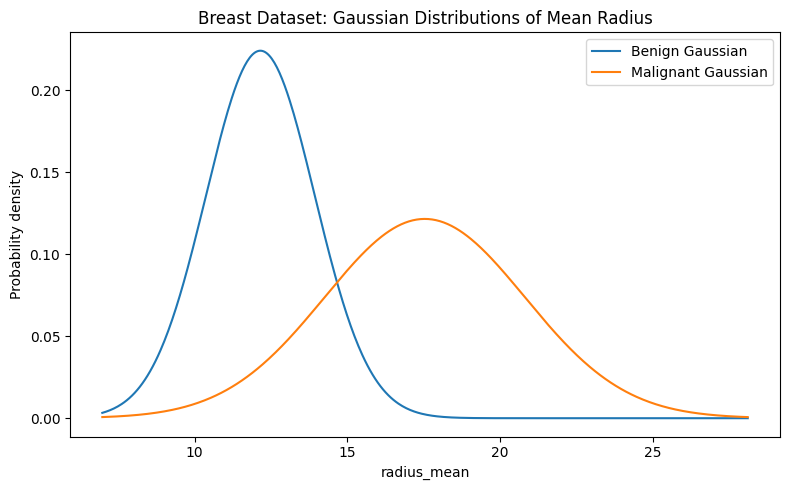

In [8]:
breast_prepared = prep_train_test(breast_X, breast_y, 'Breast Cancer Wisconsin (Diagnostic)')
breast_class_names = {0: 'Benign', 1: 'Malignant'}

print('Breast training class counts:')
print(breast_prepared['y_train'].value_counts().sort_index().rename(index=breast_class_names))
prior_breast = breast_prepared['y_train'].value_counts(normalize=True).sort_index()
print('\nPrior probabilities from training set:')
for class_value, probability in prior_breast.items():
    print(f'P({breast_class_names[int(class_value)]}) = {probability:.6f}')
print('Prior sum =', float(prior_breast.sum()))

# Conditional probability demonstration using the training-set median radius.
breast_train_X = breast_prepared['X_train']
breast_train_y = breast_prepared['y_train']
radius_median = float(breast_train_X['radius_mean'].median())
condition = breast_train_X['radius_mean'] > radius_median
p_radius_condition = float(condition.mean())
p_malignant_given_radius = float(breast_train_y.loc[condition].mean())
print('\nConditional probability illustration (training data):')
print('Median radius_mean:', radius_median)
print('P(radius_mean > median):', p_radius_condition)
print('P(Malignant | radius_mean > median):', p_malignant_given_radius)

print('\nGaussian parameter estimates for radius_mean:')
for class_value, class_name in breast_class_names.items():
    values = breast_train_X.loc[breast_train_y == class_value, 'radius_mean'].to_numpy()
    print(f'{class_name}: mean={np.mean(values):.5f}, variance_MLE={np.var(values, ddof=0):.5f}')

print('\nSingle-feature likelihood and Bayes demonstration for radius_mean:')
breast_one_feature_demo = run_single_feature_bayes_demo(breast_prepared, 'radius_mean', breast_class_names)

# Class-specific Gaussian density curves for radius_mean.
x_curve = np.linspace(breast_train_X['radius_mean'].min(), breast_train_X['radius_mean'].max(), 500)
fig, ax = plt.subplots(figsize=(8, 5))
for class_value, class_name in breast_class_names.items():
    values = breast_train_X.loc[breast_train_y == class_value, 'radius_mean'].to_numpy()
    ax.plot(x_curve, gaussian_pdf(x_curve, np.mean(values), np.var(values, ddof=0)), label=f'{class_name} Gaussian')
ax.set_xlabel('radius_mean')
ax.set_ylabel('Probability density')
ax.set_title('Breast Dataset: Gaussian Distributions of Mean Radius')
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'breast_gaussian_radius_curves.png'), dpi=220, bbox_inches='tight')
plt.show()

## 8. Breast experiment — train, validate and evaluate models

The scratch Gaussian Naive Bayes model is the primary model. Scikit-learn GaussianNB checks our implementation. Logistic Regression is the comparison model. Balanced Logistic Regression changes the penalty for class mistakes to give more attention to the less frequent class. The prior baseline provides a simple reference point.

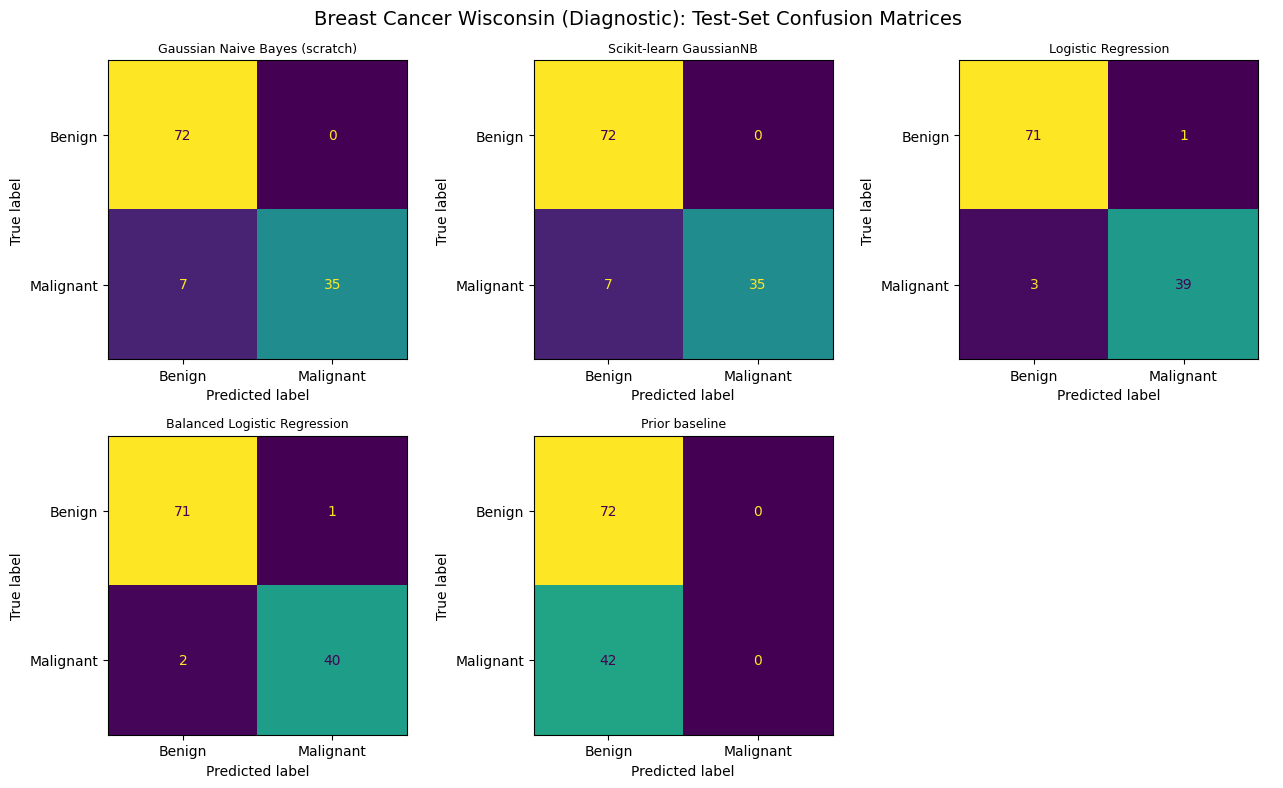

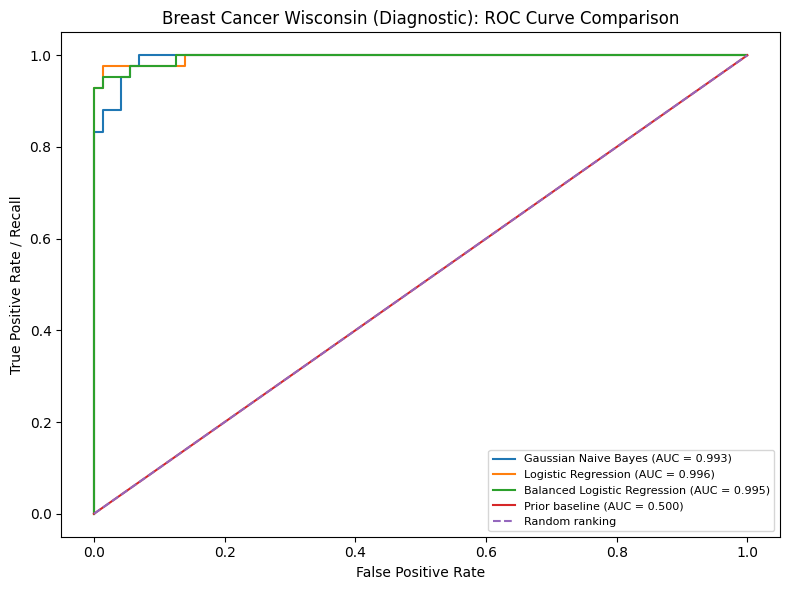

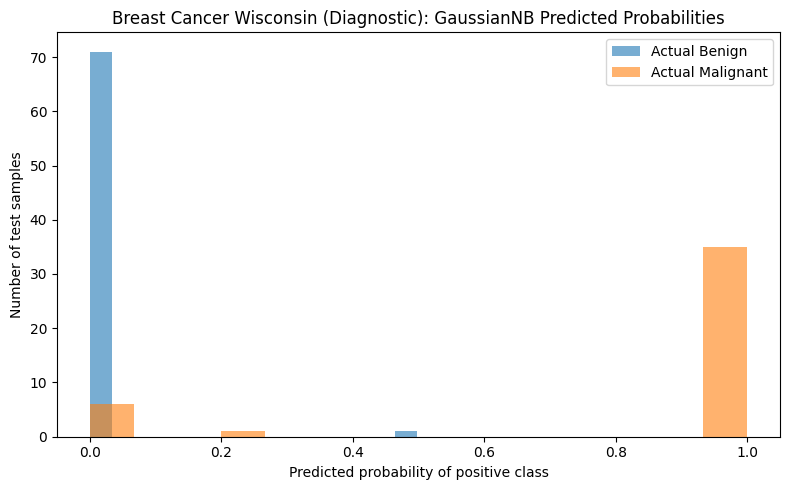


Breast Cancer Wisconsin (Diagnostic) — train/test sizes
Training: (455, 30) | Testing: (114, 30)
Training target counts: {0: 285, 1: 170}
Test target counts: {0: 72, 1: 42}
Features dropped for >50% missing in training: []
Constant features dropped based on training data: []
Retained feature count: 30

Scratch-vs-Scikit-learn GaussianNB validation:
{'Dataset': 'Breast Cancer Wisconsin (Diagnostic)', 'Differing predictions': 0, 'Maximum absolute positive-probability difference': 7.771561172376096e-16, 'Scratch epsilon': 0.00033838174019611156, 'Scikit-learn epsilon': 0.00033838174019611156}

Test-set metrics:


,Dataset,Model,Accuracy,Balanced Accuracy,Precision (positive class),Recall (positive class),F1 (positive class),ROC-AUC,Average Precision (PR-AUC)
0,Breast Cancer Wisconsin (Diagnostic),Gaussian Naive Bayes (scratch),0.9386,0.9167,1.0000,0.8333,0.9091,0.9934,0.9890
1,Breast Cancer Wisconsin (Diagnostic),Scikit-learn GaussianNB,0.9386,0.9167,1.0000,0.8333,0.9091,0.9934,0.9890
2,Breast Cancer Wisconsin (Diagnostic),Logistic Regression,0.9649,0.9573,0.9750,0.9286,0.9512,0.9960,0.9943
3,Breast Cancer Wisconsin (Diagnostic),Balanced Logistic Regression,0.9737,0.9692,0.9756,0.9524,0.9639,0.9954,0.9931
4,Breast Cancer Wisconsin (Diagnostic),Prior baseline,0.6316,0.5000,0.0000,0.0000,0.0000,0.5000,0.3684



Classification report — scratch GaussianNB:
              precision    recall  f1-score   support

      Benign       0.91      1.00      0.95        72
   Malignant       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



In [9]:
breast_results = run_experiment(breast_prepared, breast_class_names, 'breast')
breast_metrics = breast_results['metrics'].copy()
breast_validation = breast_results['validation']

## 9. Cervical experiment — probability calculations

For the second experiment, the target is the dataset's `Biopsy` outcome, not one of the other screening-test columns. We use selected demographic, habit and history variables as inputs. The dataset is imbalanced: positive biopsy outcomes are much less common than negative outcomes, so recall and precision-recall AUC matter alongside accuracy.

Cervical training class counts:
Biopsy
Biopsy negative    625
Biopsy positive     43
Name: count, dtype: int64

Prior probabilities from training set:
P(Biopsy negative) = 0.935629
P(Biopsy positive) = 0.064371
Prior sum = 1.0

Conditional probability illustration (training data):
Median Age: 26.0
P(Age > median): 0.45808383233532934
P(Biopsy positive | Age > median): 0.06862745098039216

Gaussian parameter estimates for Age by biopsy outcome:
Biopsy negative: mean=26.89120, variance_MLE=72.60256
Biopsy positive: mean=28.39535, variance_MLE=84.14602

Single-feature likelihood and Bayes demonstration for Age:
Biopsy negative: training mean=26.89120, variance=72.60256, prior=0.93563
  Gaussian density f(41.00000 | Biopsy negative) = 0.01188694
Biopsy positive: training mean=28.39535, variance=84.14602, prior=0.06437
  Gaussian density f(41.00000 | Biopsy positive) = 0.01691978

First test sample feature: Age = 41.0
Actual target: Biopsy negative
Posterior from this ONE FEATURE only:
  P(

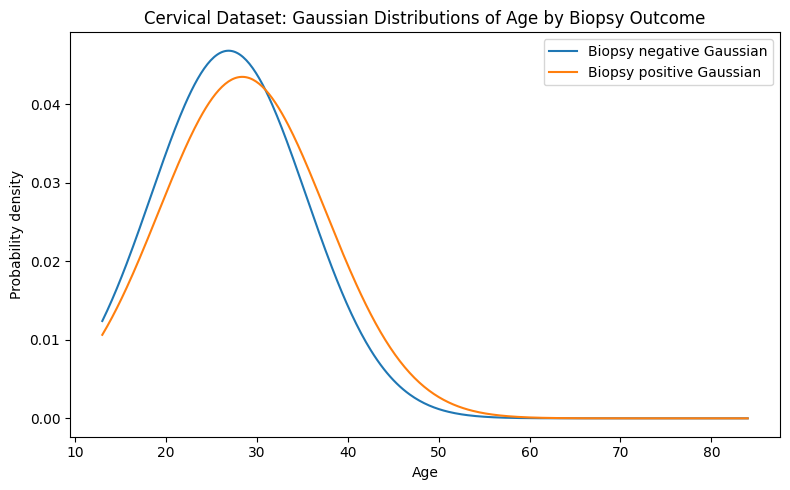

In [10]:
cervical_prepared = prep_train_test(cervical_X, cervical_y, 'Cervical Cancer Risk Factors (Biopsy outcome)')
cervical_class_names = {0: 'Biopsy negative', 1: 'Biopsy positive'}

print('Cervical training class counts:')
print(cervical_prepared['y_train'].value_counts().sort_index().rename(index=cervical_class_names))
prior_cervical = cervical_prepared['y_train'].value_counts(normalize=True).sort_index()
print('\nPrior probabilities from training set:')
for class_value, probability in prior_cervical.items():
    print(f'P({cervical_class_names[int(class_value)]}) = {probability:.6f}')
print('Prior sum =', float(prior_cervical.sum()))

# Conditional probability illustration using age above the training median.
cervical_train_X = cervical_prepared['X_train']
cervical_train_y = cervical_prepared['y_train']
age_median = float(cervical_train_X['Age'].median())
age_condition = cervical_train_X['Age'] > age_median
p_age_condition = float(age_condition.mean())
p_biopsy_positive_given_age = float(cervical_train_y.loc[age_condition].mean())
print('\nConditional probability illustration (training data):')
print('Median Age:', age_median)
print('P(Age > median):', p_age_condition)
print('P(Biopsy positive | Age > median):', p_biopsy_positive_given_age)

print('\nGaussian parameter estimates for Age by biopsy outcome:')
for class_value, class_name in cervical_class_names.items():
    values = cervical_train_X.loc[cervical_train_y == class_value, 'Age'].to_numpy()
    print(f'{class_name}: mean={np.mean(values):.5f}, variance_MLE={np.var(values, ddof=0):.5f}')

print('\nSingle-feature likelihood and Bayes demonstration for Age:')
cervical_one_feature_demo = run_single_feature_bayes_demo(cervical_prepared, 'Age', cervical_class_names)

# Class-specific Gaussian density curves for Age; positive class is rare, so this is illustrative rather than diagnostic.
age_curve = np.linspace(cervical_train_X['Age'].min(), cervical_train_X['Age'].max(), 400)
fig, ax = plt.subplots(figsize=(8, 5))
for class_value, class_name in cervical_class_names.items():
    values = cervical_train_X.loc[cervical_train_y == class_value, 'Age'].to_numpy()
    ax.plot(age_curve, gaussian_pdf(age_curve, np.mean(values), np.var(values, ddof=0)), label=f'{class_name} Gaussian')
ax.set_xlabel('Age')
ax.set_ylabel('Probability density')
ax.set_title('Cervical Dataset: Gaussian Distributions of Age by Biopsy Outcome')
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'cervical_gaussian_age_curves.png'), dpi=220, bbox_inches='tight')
plt.show()

## 10. Cervical experiment — train, validate and evaluate models

The same experimental procedure is used, with the cervical `Biopsy` outcome as the positive class. The notebook reports how many positive cases each model detects and also compares against a prior baseline. Since there are relatively few positive biopsy outcomes, the scores may vary considerably between data splits.

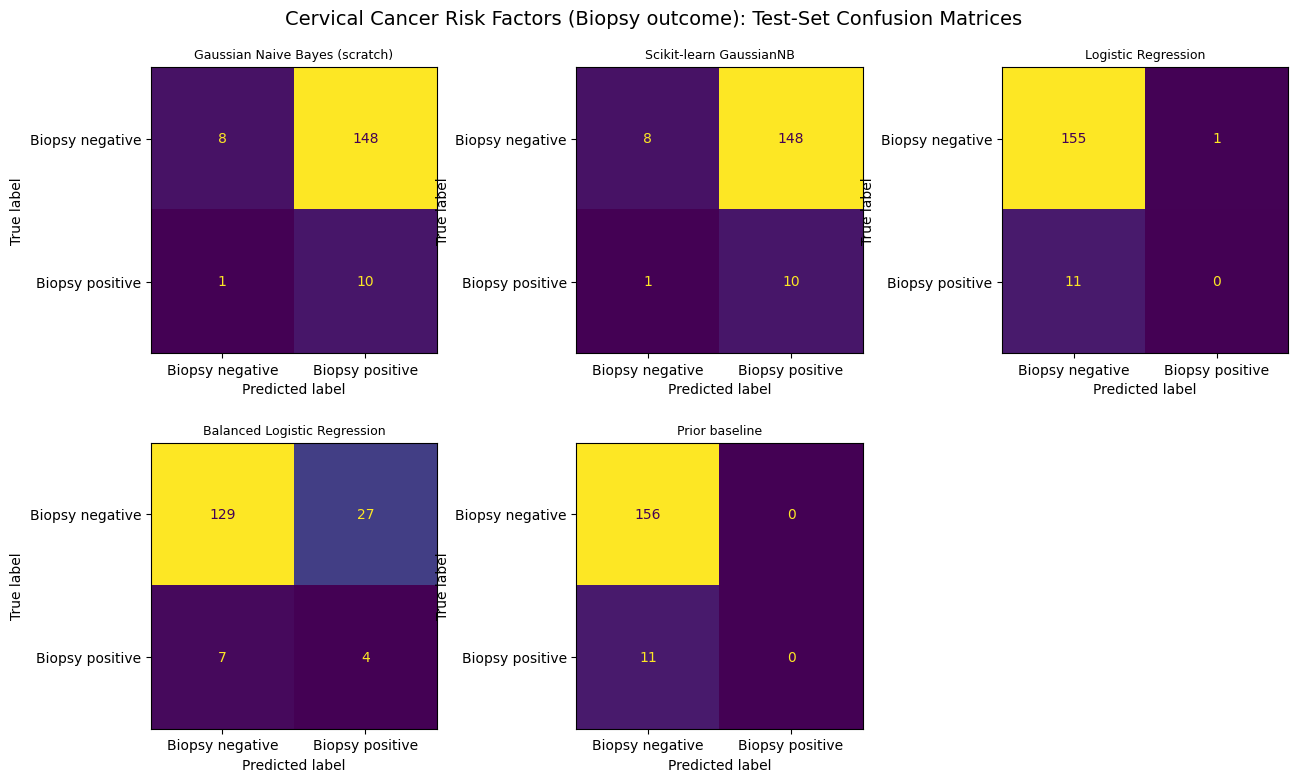

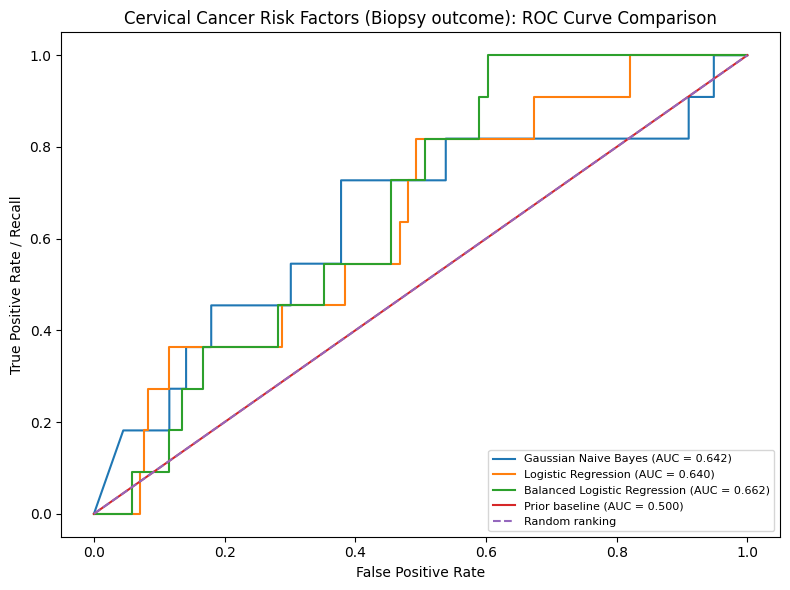

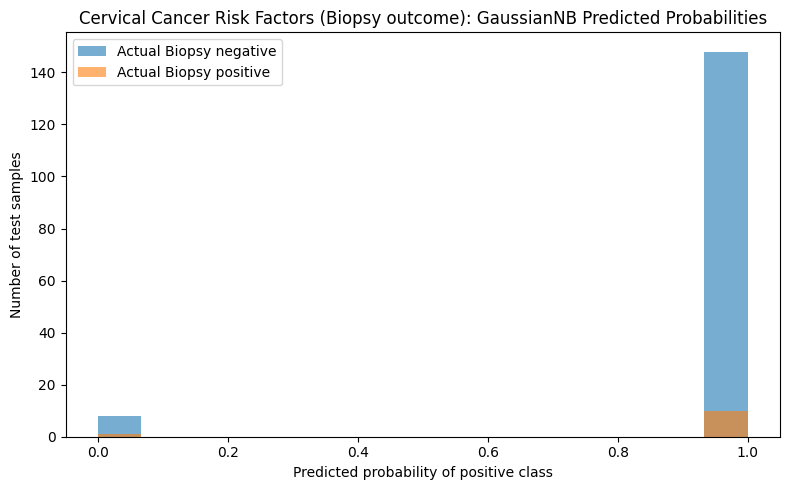


Cervical Cancer Risk Factors (Biopsy outcome) — train/test sizes
Training: (668, 24) | Testing: (167, 24)
Training target counts: {0: 625, 1: 43}
Test target counts: {0: 156, 1: 11}
Features dropped for >50% missing in training: ['STDs: Time since first diagnosis', 'STDs: Time since last diagnosis']
Constant features dropped based on training data: ['STDs:cervical condylomatosis', 'STDs:AIDS']
Retained feature count: 24

Scratch-vs-Scikit-learn GaussianNB validation:
{'Dataset': 'Cervical Cancer Risk Factors (Biopsy outcome)', 'Differing predictions': 0, 'Maximum absolute positive-probability difference': 1.7763568394002505e-15, 'Scratch epsilon': 7.348189250242031e-08, 'Scikit-learn epsilon': 7.348189250242031e-08}

Test-set metrics:


,Dataset,Model,Accuracy,Balanced Accuracy,Precision (positive class),Recall (positive class),F1 (positive class),ROC-AUC,Average Precision (PR-AUC)
0,Cervical Cancer Risk Factors (Biopsy outcome),Gaussian Naive Bayes (scratch),0.1078,0.4802,0.0633,0.9091,0.1183,0.6422,0.1330
1,Cervical Cancer Risk Factors (Biopsy outcome),Scikit-learn GaussianNB,0.1078,0.4802,0.0633,0.9091,0.1183,0.6416,0.1290
2,Cervical Cancer Risk Factors (Biopsy outcome),Logistic Regression,0.9281,0.4968,0.0000,0.0000,0.0000,0.6404,0.1128
3,Cervical Cancer Risk Factors (Biopsy outcome),Balanced Logistic Regression,0.7964,0.5953,0.1290,0.3636,0.1905,0.6620,0.1050
4,Cervical Cancer Risk Factors (Biopsy outcome),Prior baseline,0.9341,0.5000,0.0000,0.0000,0.0000,0.5000,0.0659



Classification report — scratch GaussianNB:
                 precision    recall  f1-score   support

Biopsy negative       0.89      0.05      0.10       156
Biopsy positive       0.06      0.91      0.12        11

       accuracy                           0.11       167
      macro avg       0.48      0.48      0.11       167
   weighted avg       0.83      0.11      0.10       167



In [11]:
cervical_results = run_experiment(cervical_prepared, cervical_class_names, 'cervical')
cervical_metrics = cervical_results['metrics'].copy()
cervical_validation = cervical_results['validation']

## 11. Five-fold cross-validation on training data

One 80:20 split gives one estimate of performance. As an additional robustness check, we now perform **stratified five-fold cross-validation on the training portion only** for Scikit-learn GaussianNB, Logistic Regression, balanced Logistic Regression and the prior baseline. Preprocessing steps are fitted separately inside each fold.

The cervical dataset has few positive biopsy cases, so fold-level recall and precision can be variable. Treat the cross-validation averages and standard deviations as estimates, not guarantees.

In [12]:
breast_cv = run_training_cv(breast_prepared, 'Breast Cancer Wisconsin (Diagnostic)')
cervical_cv = run_training_cv(cervical_prepared, 'Cervical Cancer Risk Factors (Biopsy outcome)')
cv_results = pd.concat([breast_cv, cervical_cv], ignore_index=True)
print('Five-fold cross-validation results (training data only; mean and standard deviation):')
display(cv_results.style.format({c: '{:.3f}' for c in cv_results.columns if c not in ['Dataset', 'Model']}))
cv_results.to_csv(os.path.join(RESULT_DIR, 'five_fold_cross_validation_results.csv'), index=False)

Five-fold cross-validation results (training data only; mean and standard deviation):


,Dataset,Model,accuracy mean,accuracy std,balanced_accuracy mean,balanced_accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std,roc_auc mean,roc_auc std,average_precision mean,average_precision std
0,Breast Cancer Wisconsin (Diagnostic),Scikit-learn GaussianNB,0.941,0.030,0.932,0.034,0.940,0.047,0.900,0.061,0.919,0.040,0.988,0.008,0.982,0.013
1,Breast Cancer Wisconsin (Diagnostic),Logistic Regression,0.974,0.017,0.969,0.021,0.977,0.031,0.953,0.045,0.964,0.023,0.996,0.005,0.995,0.005
2,Breast Cancer Wisconsin (Diagnostic),Balanced Logistic Regression,0.971,0.020,0.969,0.022,0.965,0.032,0.959,0.034,0.962,0.027,0.995,0.005,0.994,0.005
3,Breast Cancer Wisconsin (Diagnostic),Prior baseline,0.626,0.000,0.500,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.374,0.000
4,Cervical Cancer Risk Factors (Biopsy outcome),Scikit-learn GaussianNB,0.106,0.010,0.522,0.005,0.067,0.004,1.000,0.000,0.126,0.007,0.609,0.133,0.158,0.071
5,Cervical Cancer Risk Factors (Biopsy outcome),Logistic Regression,0.931,0.003,0.509,0.025,0.067,0.149,0.025,0.056,0.036,0.081,0.581,0.120,0.144,0.069
6,Cervical Cancer Risk Factors (Biopsy outcome),Balanced Logistic Regression,0.765,0.017,0.604,0.084,0.117,0.041,0.419,0.180,0.183,0.066,0.581,0.132,0.147,0.085
7,Cervical Cancer Risk Factors (Biopsy outcome),Prior baseline,0.936,0.004,0.500,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.064,0.004


## 12. Combined results table — keep the datasets separate

This table puts the two experiments into one report-ready table, but it does **not** mean the datasets were merged. The target labels differ: breast benign/malignant versus cervical biopsy negative/positive. Metrics should be interpreted within each dataset and task.

Test-set model comparison for both datasets:


,Dataset,Model,Accuracy,Balanced Accuracy,Precision (positive class),Recall (positive class),F1 (positive class),ROC-AUC,Average Precision (PR-AUC)
0,Breast Cancer Wisconsin (Diagnostic),Gaussian Naive Bayes (scratch),0.9386,0.9167,1.0000,0.8333,0.9091,0.9934,0.9890
1,Breast Cancer Wisconsin (Diagnostic),Scikit-learn GaussianNB,0.9386,0.9167,1.0000,0.8333,0.9091,0.9934,0.9890
2,Breast Cancer Wisconsin (Diagnostic),Logistic Regression,0.9649,0.9573,0.9750,0.9286,0.9512,0.9960,0.9943
3,Breast Cancer Wisconsin (Diagnostic),Balanced Logistic Regression,0.9737,0.9692,0.9756,0.9524,0.9639,0.9954,0.9931
4,Breast Cancer Wisconsin (Diagnostic),Prior baseline,0.6316,0.5000,0.0000,0.0000,0.0000,0.5000,0.3684
5,Cervical Cancer Risk Factors (Biopsy outcome),Gaussian Naive Bayes (scratch),0.1078,0.4802,0.0633,0.9091,0.1183,0.6422,0.1330
6,Cervical Cancer Risk Factors (Biopsy outcome),Scikit-learn GaussianNB,0.1078,0.4802,0.0633,0.9091,0.1183,0.6416,0.1290
7,Cervical Cancer Risk Factors (Biopsy outcome),Logistic Regression,0.9281,0.4968,0.0000,0.0000,0.0000,0.6404,0.1128
8,Cervical Cancer Risk Factors (Biopsy outcome),Balanced Logistic Regression,0.7964,0.5953,0.1290,0.3636,0.1905,0.6620,0.1050
9,Cervical Cancer Risk Factors (Biopsy outcome),Prior baseline,0.9341,0.5000,0.0000,0.0000,0.0000,0.5000,0.0659


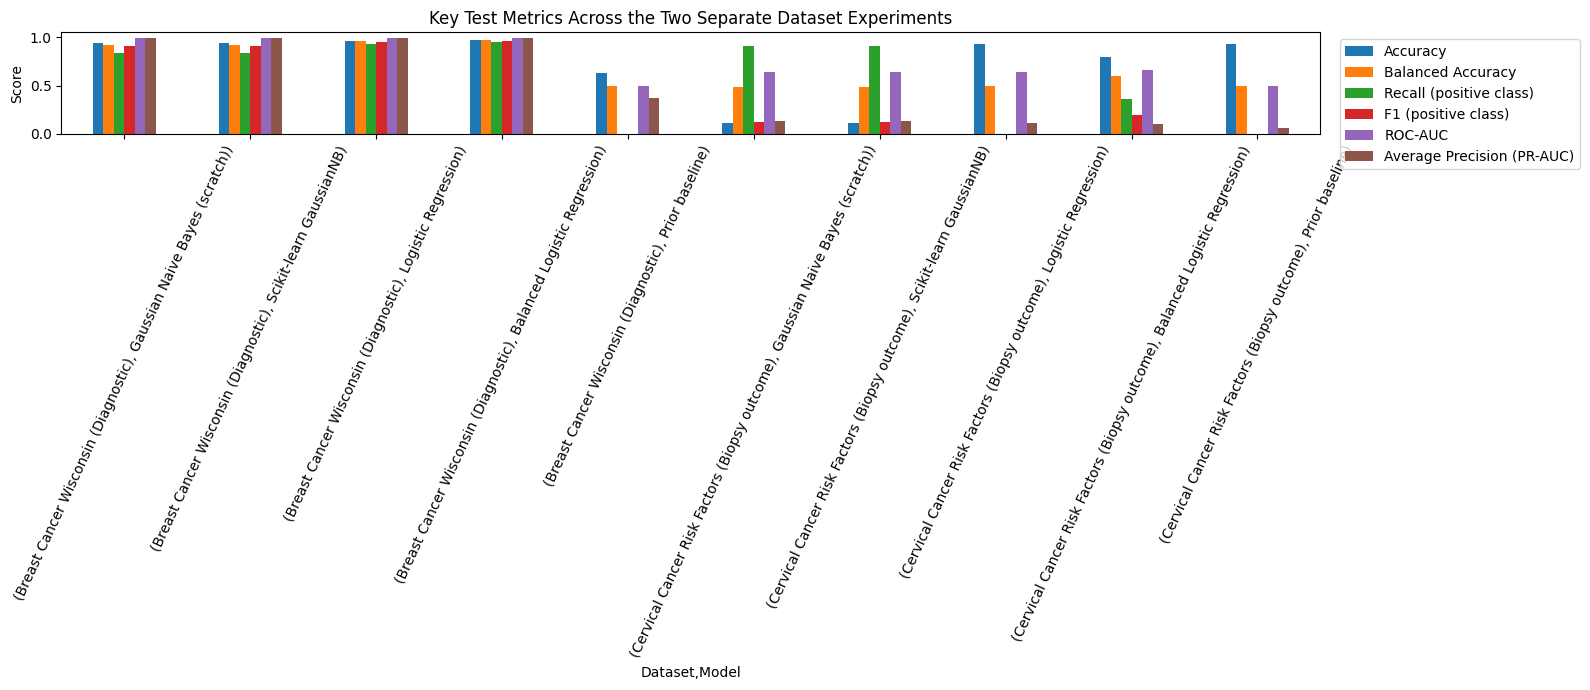

In [13]:
all_test_metrics = pd.concat([breast_metrics, cervical_metrics], ignore_index=True)
all_test_metrics.to_csv(os.path.join(RESULT_DIR, 'multi_dataset_test_metrics.csv'), index=False)
print('Test-set model comparison for both datasets:')
display(all_test_metrics.style.format({c: '{:.4f}' for c in all_test_metrics.columns if c not in ['Dataset', 'Model']}))

# Plot the key metrics while labelling dataset/model combinations explicitly.
key_metrics = ['Accuracy', 'Balanced Accuracy', 'Recall (positive class)', 'F1 (positive class)', 'ROC-AUC', 'Average Precision (PR-AUC)']
plot_df = all_test_metrics.set_index(['Dataset', 'Model'])[key_metrics]
ax = plot_df.plot(kind='bar', figsize=(16, 7))
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Key Test Metrics Across the Two Separate Dataset Experiments')
ax.tick_params(axis='x', labelrotation=65)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'multi_dataset_metric_comparison.png'), dpi=220, bbox_inches='tight')
plt.show()

## 13. Scratch Gaussian Naive Bayes validation summary

We compare the predictions from our implementation with Scikit-learn GaussianNB on the same train/test split and the same imputed feature matrix. Exact or near-exact agreement validates that our probability calculations reproduce the standard implementation for these experiments.

In [14]:
validation_summary = pd.DataFrame([breast_validation, cervical_validation])
display(validation_summary)
validation_summary.to_csv(os.path.join(RESULT_DIR, 'gaussian_nb_implementation_validation.csv'), index=False)

for item in [breast_validation, cervical_validation]:
    print(f"{item['Dataset']}: {item['Differing predictions']} differing predictions; max positive-probability difference={item['Maximum absolute positive-probability difference']:.3e}")

,Dataset,Differing predictions,Maximum absolute positive-probability difference,Scratch epsilon,Scikit-learn epsilon
0,Breast Cancer Wisconsin (Diagnostic),0,7.771561e-16,3.383817e-04,3.383817e-04
1,Cervical Cancer Risk Factors (Biopsy outcome),0,1.776357e-15,7.348189e-08,7.348189e-08


Breast Cancer Wisconsin (Diagnostic): 0 differing predictions; max positive-probability difference=7.772e-16
Cervical Cancer Risk Factors (Biopsy outcome): 0 differing predictions; max positive-probability difference=1.776e-15


## 14. Limitations and interpretation

1. The breast experiment predicts the dataset's benign/malignant diagnosis label from cell-nucleus measurements.
2. The cervical experiment predicts a recorded biopsy outcome using selected risk-factor/history variables. It is not a full clinical cervical-cancer diagnostic system.
3. Diagnostic and screening outcome columns were excluded from cervical predictors to reduce leakage; the target remains `Biopsy`.
4. Exact duplicate cervical rows were removed before splitting. That reduces the risk of identical rows appearing in both training and test sets, though identical records can sometimes occur naturally when a dataset contains coarse/binary values.
5. The cervical target is strongly imbalanced. Accuracy must be interpreted alongside recall, precision, F1, balanced accuracy and average precision.
6. Gaussian Naive Bayes assumes features are conditionally independent given the class and models features with Gaussian distributions. The cervical features include binary and discrete values, so the Gaussian assumption is an approximation.
7. A fixed test split and cross-validation are not external validation. Results may differ on new populations or independently collected data.
8. These experiments are for academic learning and must not be used to diagnose or guide treatment for any patient.

## 15. Save the notebook's main result files

The notebook saves the following outputs under the project folder:

- `results/breast_test_predictions.csv`
- `results/cervical_test_predictions.csv`
- `results/multi_dataset_test_metrics.csv`
- `results/five_fold_cross_validation_results.csv`
- `results/gaussian_nb_implementation_validation.csv`
- Diagnostic plots under `figures/`

Run this final cell to confirm the generated files.

In [15]:
print('FINAL SUMMARY')
print('=' * 60)
print('Breast dataset: raw rows =', len(breast_raw), '| model rows =', len(breast_y), '| features before training-only filtering =', breast_X.shape[1])
print('Cervical dataset: raw rows =', len(cervical_raw), '| model rows after exact-duplicate removal =', len(cervical_y), '| risk/history features before training-only filtering =', cervical_X.shape[1])
print('\nTest samples — breast:', len(breast_prepared['y_test']), '| cervical:', len(cervical_prepared['y_test']))
print('\nTest-metric CSV:', os.path.join(RESULT_DIR, 'multi_dataset_test_metrics.csv'))
print('Cross-validation CSV:', os.path.join(RESULT_DIR, 'five_fold_cross_validation_results.csv'))
print('Validation CSV:', os.path.join(RESULT_DIR, 'gaussian_nb_implementation_validation.csv'))
print('Figures folder:', FIG_DIR)
print('Results folder:', RESULT_DIR)
print('\nDo not describe these results as clinical validation.')

FINAL SUMMARY
Breast dataset: raw rows = 569 | model rows = 569 | features before training-only filtering = 30
Cervical dataset: raw rows = 858 | model rows after exact-duplicate removal = 835 | risk/history features before training-only filtering = 28

Test samples — breast: 114 | cervical: 167

Test-metric CSV: /mnt/data/results/multi_dataset_test_metrics.csv
Cross-validation CSV: /mnt/data/results/five_fold_cross_validation_results.csv
Validation CSV: /mnt/data/results/gaussian_nb_implementation_validation.csv
Figures folder: /mnt/data/figures
Results folder: /mnt/data/results

Do not describe these results as clinical validation.
